In [265]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.io as pio 
import plotly.express as px
import nbformat


Data Cleaning

In [ ]:

rides = ['7_dwarfs_train', 'alien_saucers', 'astro_orbiter', 'big_thunder_mtn', 'buzz_lightyear', 'dinosaur', 'dumbo', 'expedition_everest', 'flight_of_passage', 'haunted_mansion', 'jungle_cruise', 'kilimanjaro_safaris', 'mad_tea_party', 'magic_carpets', 'navi_river', 'peoplemover', 'peter_pan_s_flight', 'pirates_of_caribbean', 'rock_n_rollercoaster', 'slinky_dog', 'soarin', 'space_mountain', 'splash_mountain', 'tom_land_speedway', 'toy_story_mania', 'winnie_the_pooh']
dfs = []
for ride in rides:
    df = pd.read_csv(f'/Users/brittneychan/Desktop/disneypred/data/raw/{ride}.csv.xls')
    df['ride'] = ride
    dfs.append(df)

all_rides = pd.concat(dfs)

#Day information (year, month, day, hour, day of week)
all_rides['datetime'] = pd.to_datetime(all_rides['datetime'])

all_rides['year'] = all_rides['datetime'].dt.year
all_rides['month'] = all_rides['datetime'].dt.month
all_rides['day'] = all_rides['datetime'].dt.day
all_rides['hour'] = all_rides['datetime'].dt.hour
all_rides['day_of_week'] = all_rides['datetime'].dt.dayofweek  # 0=Monday, 6=Sunday
all_rides['weekday_name'] = all_rides['datetime'].dt.day_name()

#Clean invalid wait times
all_rides.loc[all_rides['SACTMIN'] < 0, 'SACTMIN'] = np.nan
all_rides['SPOSTMIN'] = all_rides['SPOSTMIN'].replace(-999, np.nan)
all_rides['SACTMIN'] = all_rides['SACTMIN'].replace(-999, np.nan)

# Get rid of outliers
q1 = all_rides.groupby('ride')['SACTMIN'].transform('quantile', 0.25)
q3 = all_rides.groupby('ride')['SACTMIN'].transform('quantile', 0.75)
iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr
all_rides.loc[all_rides['SACTMIN'] > upper_bound, 'SACTMIN'] = np.nan


#Imputation of wait times
all_rides['posted_wait'] = all_rides['SPOSTMIN'].fillna(all_rides['SACTMIN'])
all_rides['posted_wait'] = all_rides.groupby(['ride', 'month', 'day_of_week', 'hour'])['posted_wait'].transform(lambda x: x.fillna(x.median()))

all_rides['posted_wait'] = all_rides.groupby('ride')['posted_wait'].transform(lambda x: x.fillna(x.median()))

#Get rid of unnecessary columns
all_rides.drop(columns=['SPOSTMIN', 'SACTMIN'], inplace=True)

In [228]:
meta = pd.read_csv('/Users/brittneychan/Desktop/disneypred/data/raw/metadata.csv.xls')
season = meta[['DATE','SEASON']]
season.head()

,DATE,SEASON
0,01/01/2015,CHRISTMAS PEAK
1,01/02/2015,CHRISTMAS
2,01/03/2015,CHRISTMAS
3,01/04/2015,CHRISTMAS
4,01/05/2015,CHRISTMAS


In [335]:
#Kissimmee Weather Data 
kissimmee = pd.read_csv('/Users/brittneychan/Desktop/disneypred/data/raw/kissimmee.csv').drop(columns=['COOPID'])
kissimmee.columns = kissimmee.columns.str.strip().str.lower()

kissimmee['weatherdate'] = pd.to_datetime(kissimmee[['year', 'month', 'day']])

weather_cols = ['precipitation', 'mean temp']

# Set date as index
kissimmee = kissimmee.sort_values('weatherdate')
kissimmee = kissimmee.set_index('weatherdate')

#Impute missing values - 7 day rolling avg


kissimmee['mean temp'].replace(-99.9, np.nan, inplace=True)
kissimmee['mean temp'].rolling(
    window=7,
    center=True,
    min_periods=1
).mean()

kissimmee['precipitation'].replace(-99.99, np.nan, inplace=True)
kissimmee['precipitation'] = kissimmee['precipitation'].fillna(
    kissimmee['precipitation'].rolling(7, center=True, min_periods=1).median()
)

kissimmee = kissimmee.reset_index()
kissimmee.head()

/var/folders/hm/14j83hg521g_k5p6t8vj0zgh0000gn/T/ipykernel_16677/1897787498.py:16: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  kissimmee['mean temp'].replace(-99.9, np.nan, inplace=True)
/var/folders/hm/14j83hg521g_k5p6t8vj0zgh0000gn/T/ipykernel_16677/1897787498.py:23: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are settin

,weatherdate,year,month,day,precipitation,max temp,min temp,mean temp
0,2015-01-01,2015,1,1,0.02,65.0,58.0,61.5
1,2015-01-02,2015,1,2,0.00,75.0,59.0,67.0
2,2015-01-03,2015,1,3,0.00,77.0,61.0,69.0
3,2015-01-04,2015,1,4,0.00,85.0,67.0,76.0
4,2015-01-05,2015,1,5,0.00,86.0,66.0,76.0


In [336]:
fin = all_rides.merge(season, left_on='date', right_on='DATE', how='left').merge(
    kissimmee,
    left_on=['year', 'month', 'day'],
    right_on=['year', 'month', 'day'],
    how='left'
)
fin.drop(columns=['DATE', 'weatherdate'], inplace=True)
fin.rename(columns={'SEASON': 'season'}, inplace=True)
fin.head()

,date,datetime,ride,year,month,day,hour,day_of_week,weekday_name,posted_wait,season,precipitation,max temp,min temp,mean temp
0,01/01/2015,2015-01-01 07:51:12,7_dwarfs_train,2015,1,1,7,3,Thursday,45.0,CHRISTMAS PEAK,0.02,65.0,58.0,61.5
1,01/01/2015,2015-01-01 08:02:13,7_dwarfs_train,2015,1,1,8,3,Thursday,60.0,CHRISTMAS PEAK,0.02,65.0,58.0,61.5
2,01/01/2015,2015-01-01 08:05:30,7_dwarfs_train,2015,1,1,8,3,Thursday,54.0,CHRISTMAS PEAK,0.02,65.0,58.0,61.5
3,01/01/2015,2015-01-01 08:09:12,7_dwarfs_train,2015,1,1,8,3,Thursday,60.0,CHRISTMAS PEAK,0.02,65.0,58.0,61.5
4,01/01/2015,2015-01-01 08:16:12,7_dwarfs_train,2015,1,1,8,3,Thursday,60.0,CHRISTMAS PEAK,0.02,65.0,58.0,61.5


Exploring Data

In [232]:
print(min(fin['posted_wait']))
print(max(fin['posted_wait']))
print(fin['posted_wait'].describe())

0.0
390.0
count    6.969147e+06
mean     3.964193e+01
std      3.175113e+01
min      0.000000e+00
25%      1.500000e+01
50%      3.000000e+01
75%      5.500000e+01
max      3.900000e+02
Name: posted_wait, dtype: float64


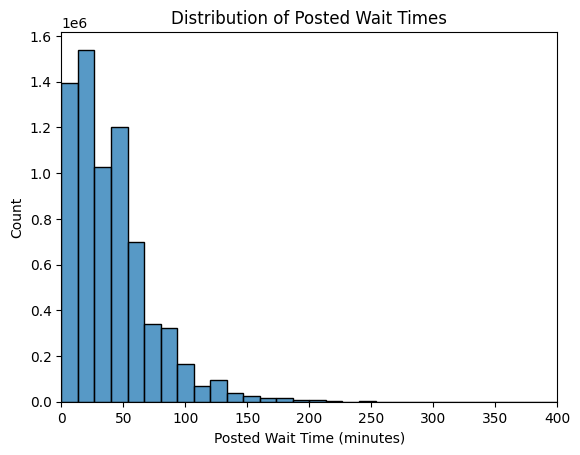

In [233]:
# Distribution of wait time
sns.histplot(fin['posted_wait'], bins=30, binrange=(0, 400))
plt.title('Distribution of Posted Wait Times')
plt.xlabel('Posted Wait Time (minutes)')
plt.xlim(0, 400)
plt.show()

ride
flight_of_passage       53.595932
space_mountain          35.376589
7_dwarfs_train          33.836941
navi_river              32.396631
rock_n_rollercoaster    31.651389
toy_story_mania         29.996143
splash_mountain         29.925376
kilimanjaro_safaris     28.293731
slinky_dog              28.091067
soarin                  27.270648
peter_pan_s_flight      24.903827
jungle_cruise           24.424845
big_thunder_mtn         23.007078
expedition_everest      22.473513
buzz_lightyear          19.584987
dinosaur                19.250036
haunted_mansion         18.729021
pirates_of_caribbean    17.862752
alien_saucers           16.106781
dumbo                   15.393380
tom_land_speedway       14.822725
winnie_the_pooh         13.777666
astro_orbiter           13.344797
magic_carpets           11.099860
peoplemover             10.026762
mad_tea_party            7.797398
Name: posted_wait, dtype: float64


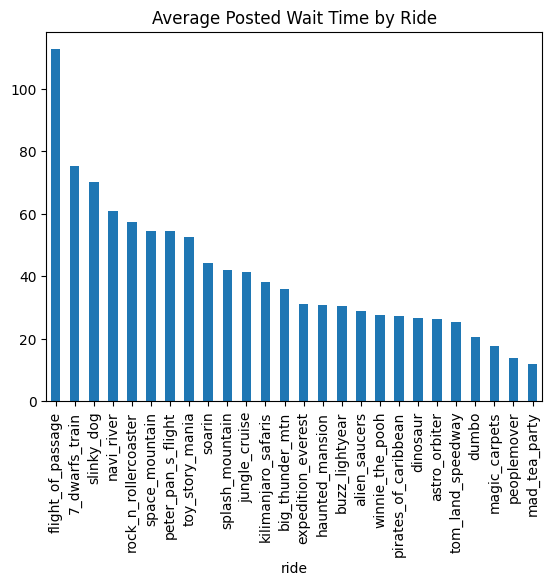

<Figure size 1200x600 with 0 Axes>

In [234]:
# Ride vs wait time
rideavg = fin.groupby('ride')['posted_wait'].mean().sort_values(ascending=False)
rideavg.plot(kind='bar')
plt.title('Average Posted Wait Time by Ride')
plt.figure(figsize=(12, 6))

print(fin.groupby('ride')['posted_wait'].std().sort_values(ascending=False))

(0.0, 24.0)

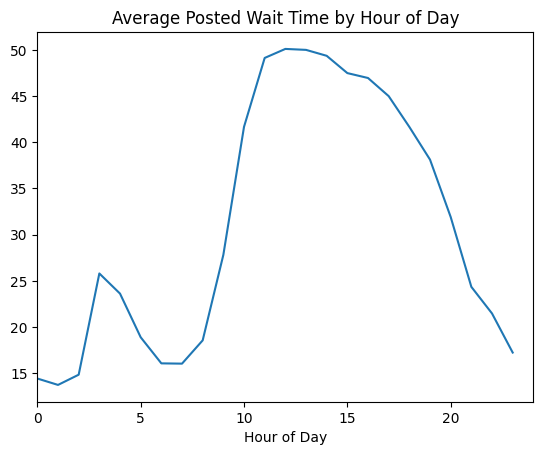

In [235]:
# Hour of day vs wait time
hourly = fin.groupby('hour')['posted_wait'].mean()
sns.lineplot(x=hourly.index, y=hourly.values)
plt.title('Average Posted Wait Time by Hour of Day')
plt.xlabel('Hour of Day')
plt.xlim(0, 24)

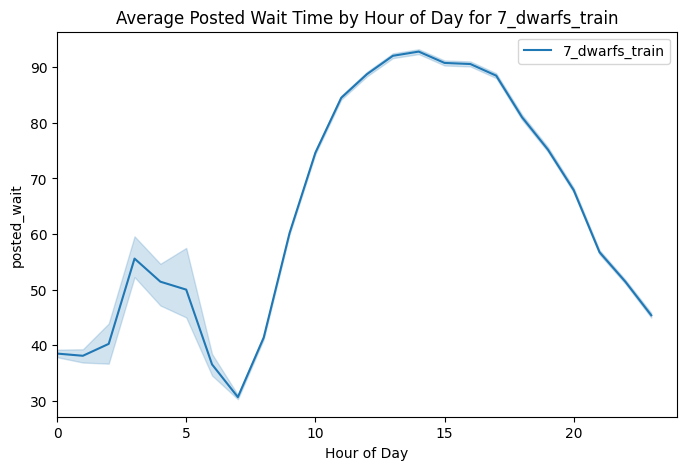

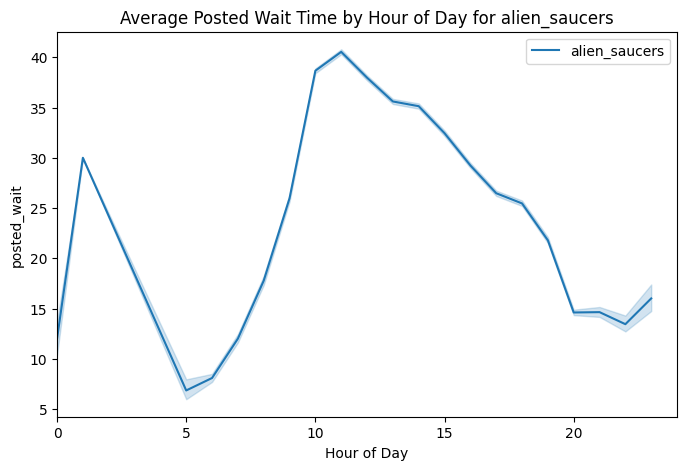

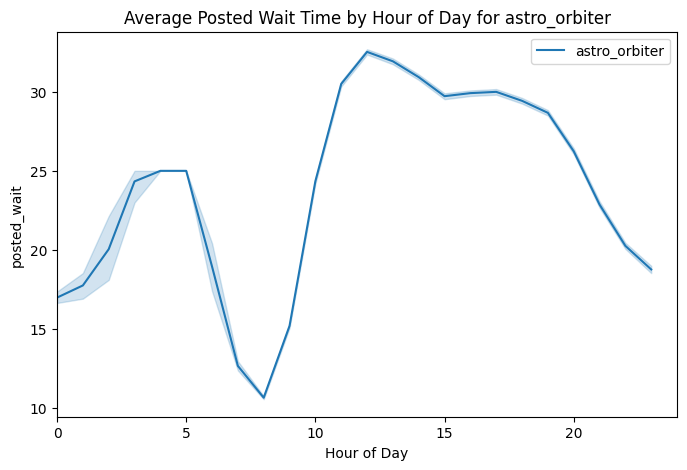

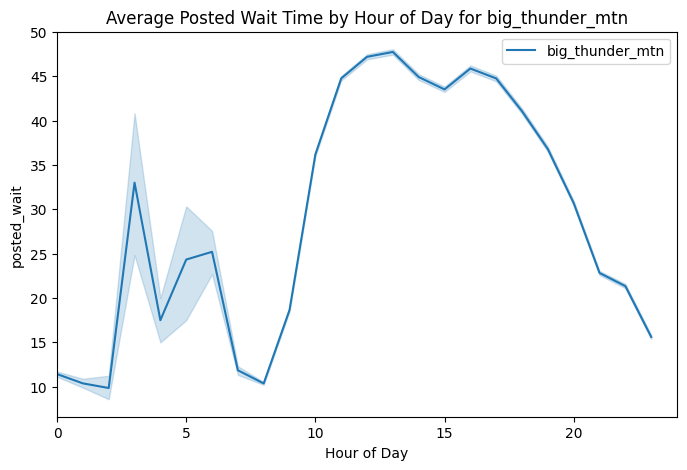

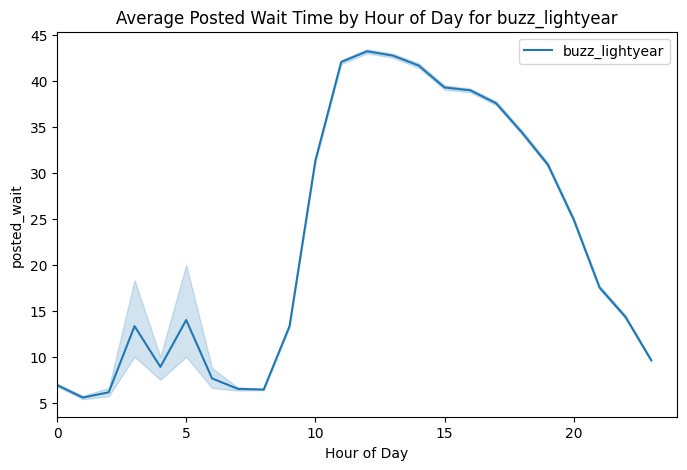

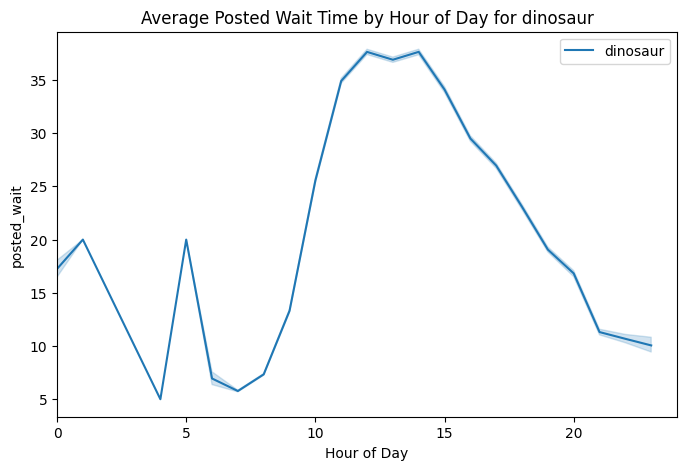

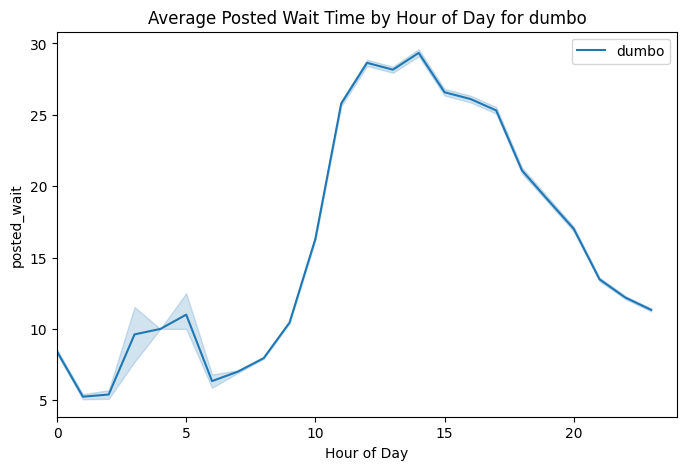

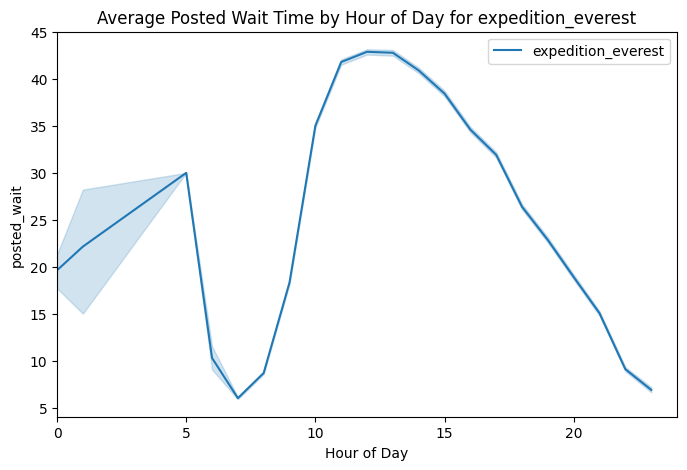

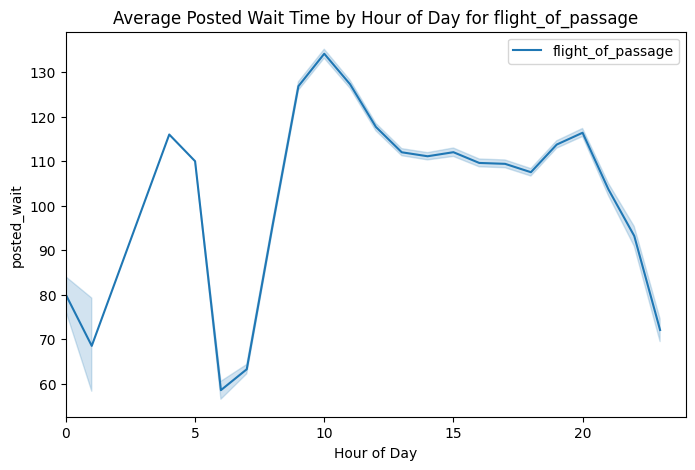

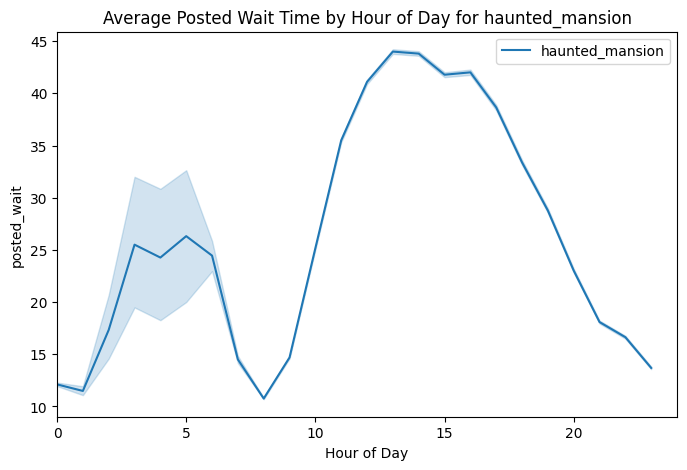

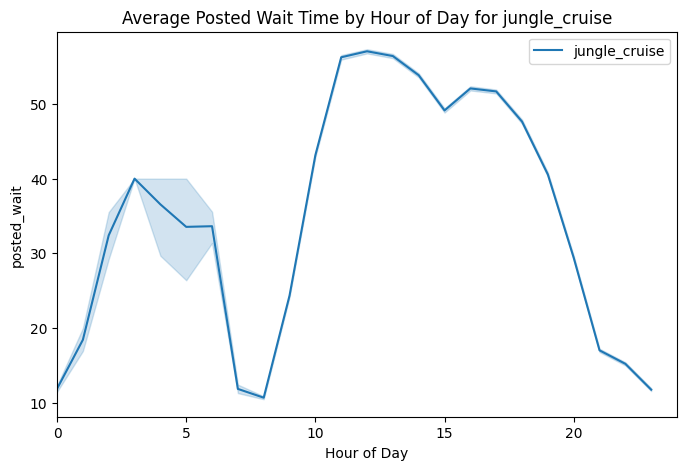

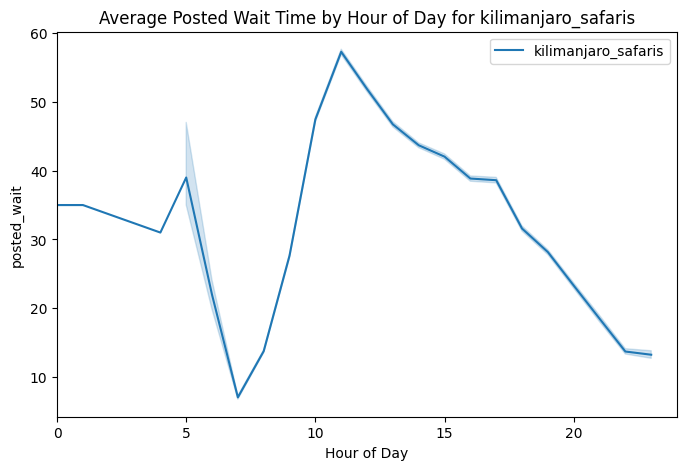

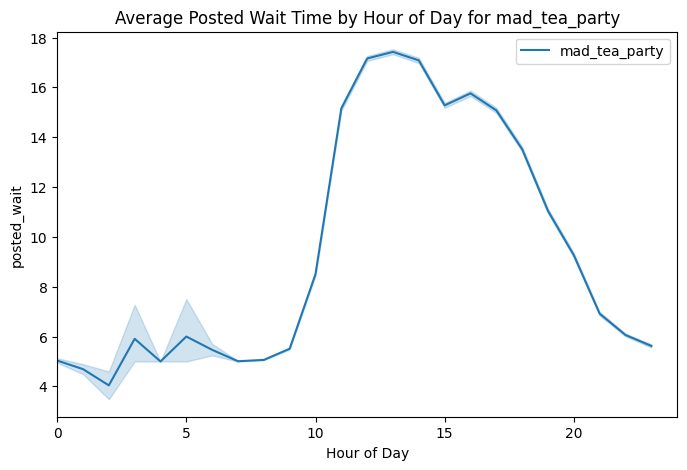

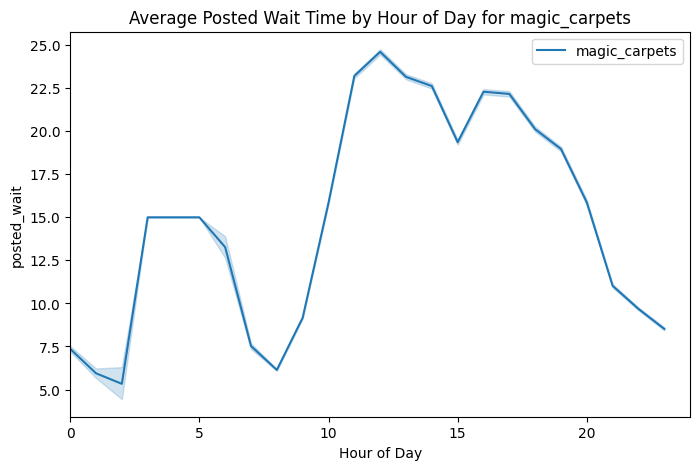

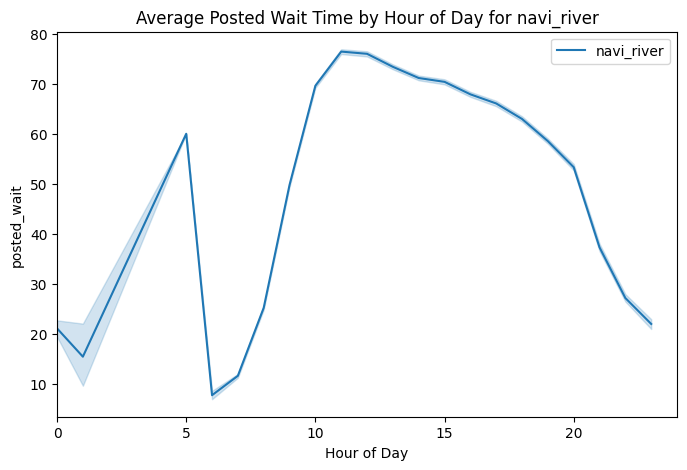

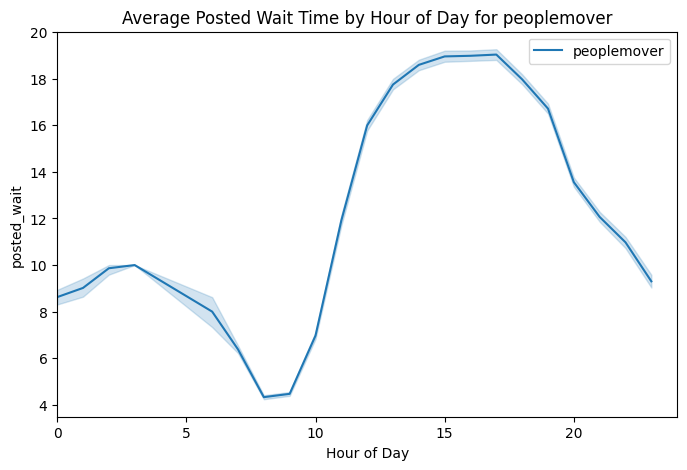

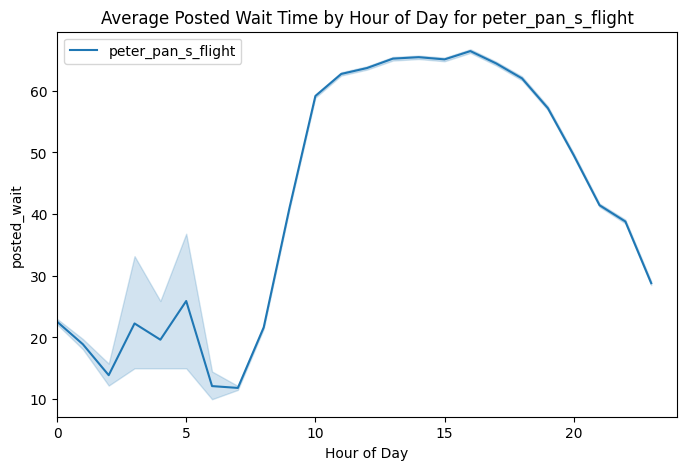

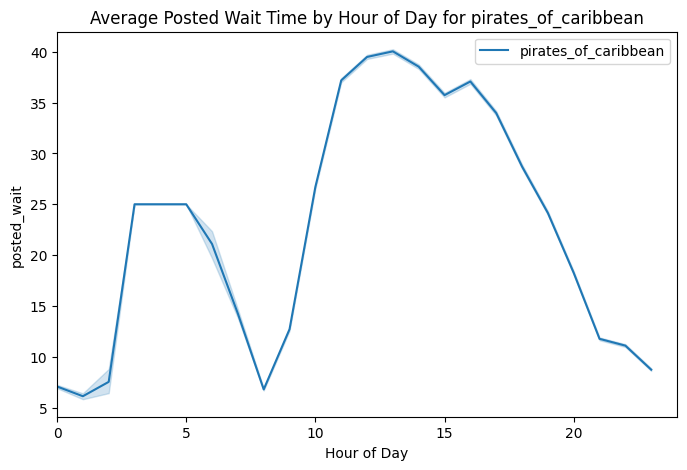

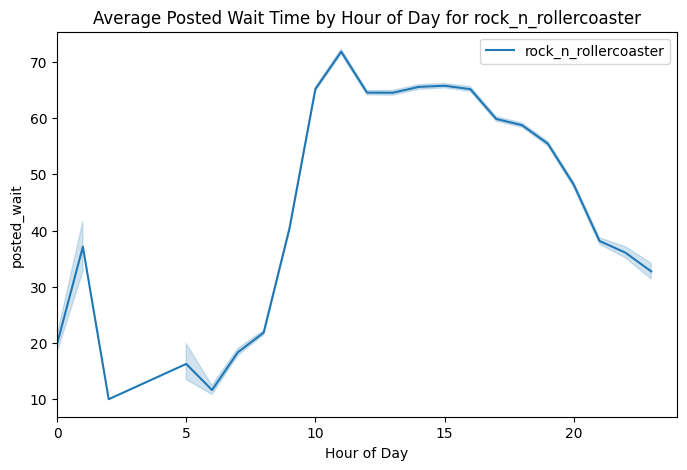

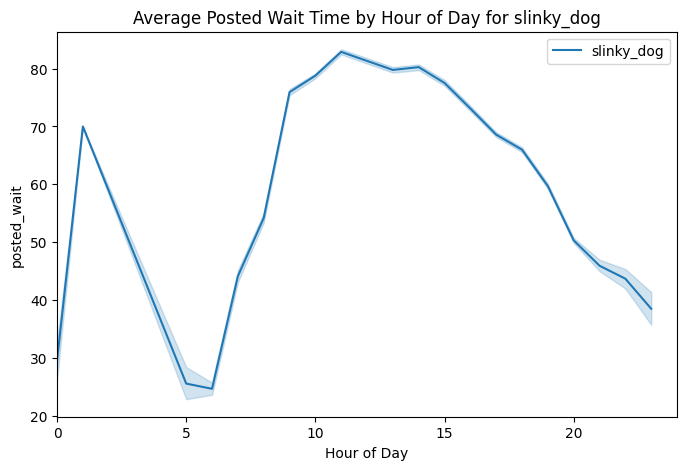

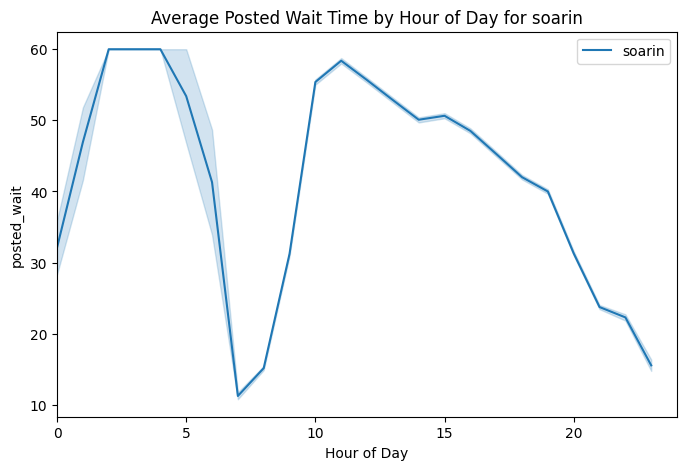

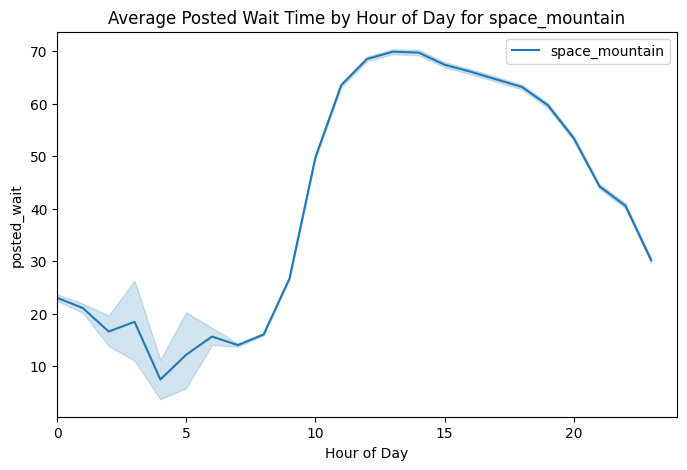

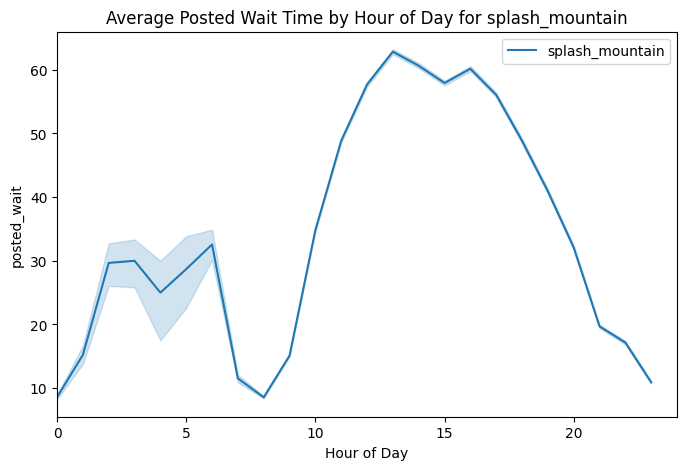

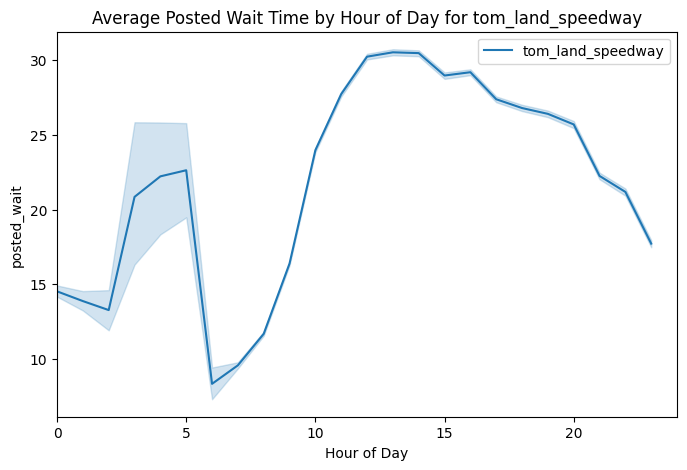

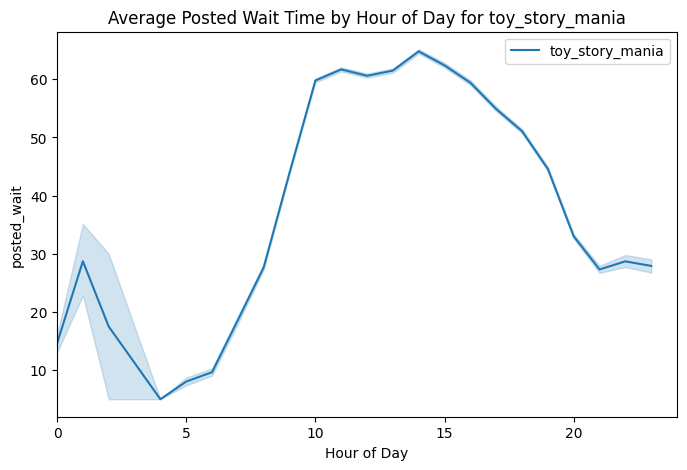

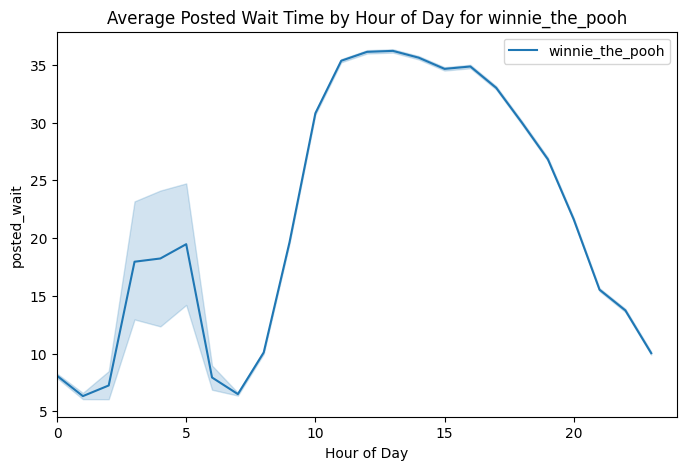

In [236]:
for ride in rides:
    ride_data = fin[fin['ride'] == ride]
    plt.figure(figsize=(8, 5))
    sns.lineplot(
        data=ride_data,
        x='hour',
        y='posted_wait',
        label=ride
    )
    plt.title(f'Average Posted Wait Time by Hour of Day for {ride}')
    plt.xlabel('Hour of Day')
    plt.xlim(0, 24)
    plt.show()

<Axes: xlabel='hour', ylabel='posted_wait'>

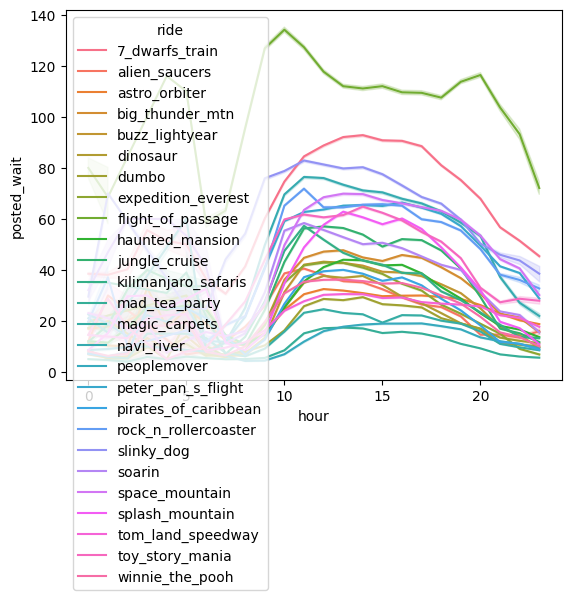

In [237]:
sns.lineplot(
    data=fin,
    x='hour',
    y='posted_wait',
    hue='ride'
)

<Axes: xlabel='day_of_week'>

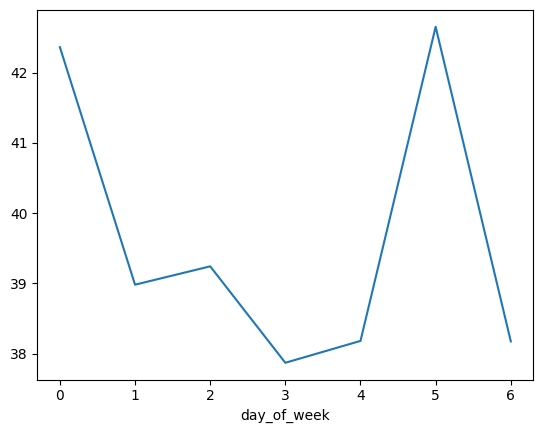

In [238]:
# Day of week vs wait time
#0 = Monday, 6 = Sunday
dayofweek = fin.groupby('day_of_week')['posted_wait'].mean()
sns.lineplot(x=dayofweek.index, y=dayofweek.values)

season
CHRISTMAS PEAK     63.126676
CHRISTMAS          49.660974
EASTER             48.109466
THANKSGIVING       48.108122
MARDI GRAS         47.583400
PRESIDENTS WEEK    47.507164
MEMORIAL DAY       46.432504
COLUMBUS DAY       44.229043
JULY 4TH           42.759622
SUMMER BREAK       42.689405
MLK JR             41.617906
SPRING             41.502309
JERSEY WEEK        40.222186
WINTER             37.473138
FALL               34.139208
HALLOWEEN          31.253956
SEPTEMBER LOW      29.460394
Name: posted_wait, dtype: float64


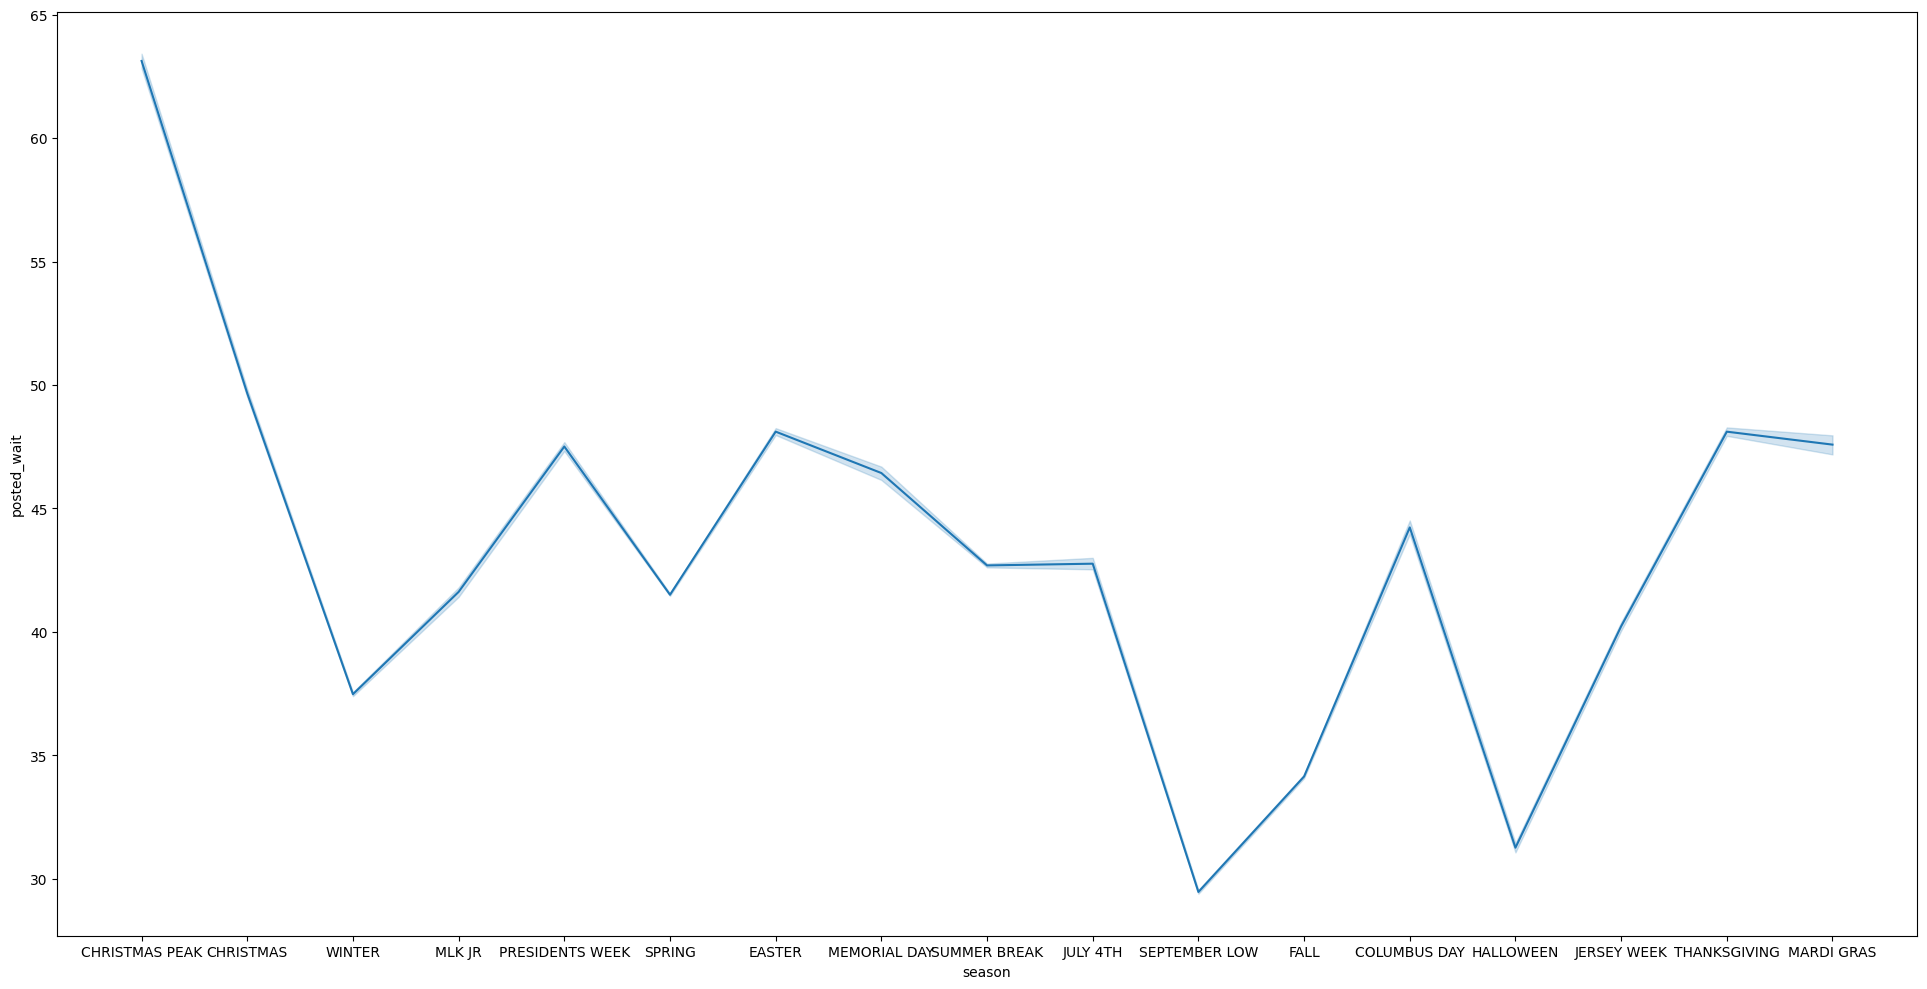

In [263]:
# Season vs wait time
mapping = {'MARTIN LUTHER KING JUNIOR DAY': 'MLK JR'}
fin['season'] = fin['season'].replace(mapping)

seasonal = fin.groupby('season')['posted_wait'].mean().sort_values(ascending=False)
print(seasonal)

plt.figure(figsize=(24, 12))
sns.lineplot(
    data=fin,
    x='season',
    y='posted_wait'
)
plt.show()

In [ ]:
# Temperature vs wait time
pio.renderers.default = "browser" 

finsample = fin.sample(n=5000).copy()
finsample['temp_step'] = finsample['mean temp'].round()
finsample = finsample.sort_values('temp_step')

fig = px.scatter(
    finsample, 
    x='mean temp', 
    y='posted_wait',
    animation_frame='temp_step',  # This creates your temperature slider!
    opacity=0.6,
    labels={'mean temp': 'Mean Temperature', 'posted_wait': 'Posted Wait Time (min)'},
    title="Wait Time vs. Temperature"
)

fig.update_layout(
    xaxis=dict(range=[finsample['mean temp'].min() - 2, finsample['mean temp'].max() + 2]),
    yaxis=dict(range=[0, finsample['posted_wait'].max() + 10])
)

fig.show()


/Users/brittneychan/Library/Python/3.9/lib/python/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: divide by zero encountered in matmul
  return _core_matmul(x1, x2)
/Users/brittneychan/Library/Python/3.9/lib/python/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: overflow encountered in matmul
  return _core_matmul(x1, x2)
/Users/brittneychan/Library/Python/3.9/lib/python/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: invalid value encountered in matmul
  return _core_matmul(x1, x2)


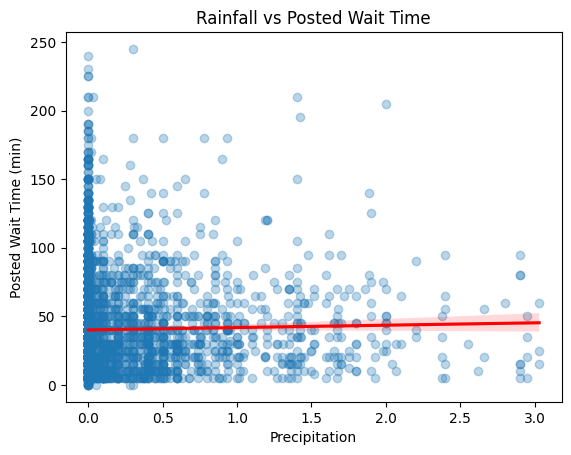

In [279]:
# Rain vs wait time
sns.regplot(
    data=fin.sample(n=5000),
    x='precipitation',
    y='posted_wait',
    scatter_kws={'alpha': 0.3},
    line_kws={'color': 'red'}
)

plt.title('Rainfall vs Posted Wait Time')
plt.xlabel('Precipitation')
plt.ylabel('Posted Wait Time (min)')
plt.show()

/var/folders/hm/14j83hg521g_k5p6t8vj0zgh0000gn/T/ipykernel_16677/771093463.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  fin.groupby(rainbins)['posted_wait']


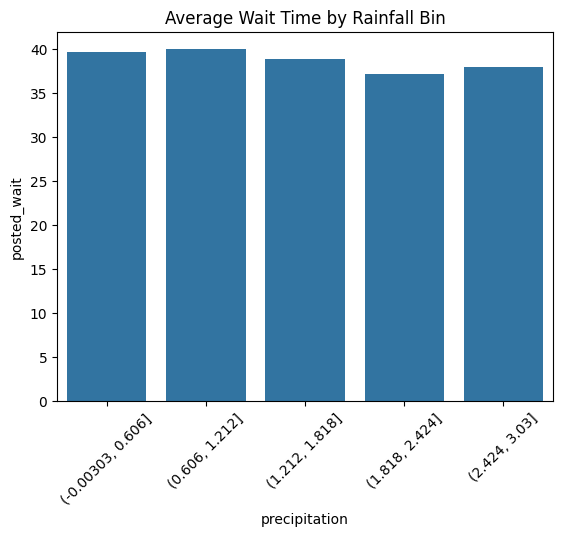

In [285]:
rainbins = pd.cut(fin['precipitation'], bins=5)

avgwait = (
    fin.groupby(rainbins)['posted_wait']
       .mean()
       .reset_index()
)

sns.barplot(
    data=avgwait,
    x='precipitation',
    y='posted_wait'
)

plt.xticks(rotation=45)
plt.title('Average Wait Time by Rainfall Bin')
plt.show()

<Axes: xlabel='date'>

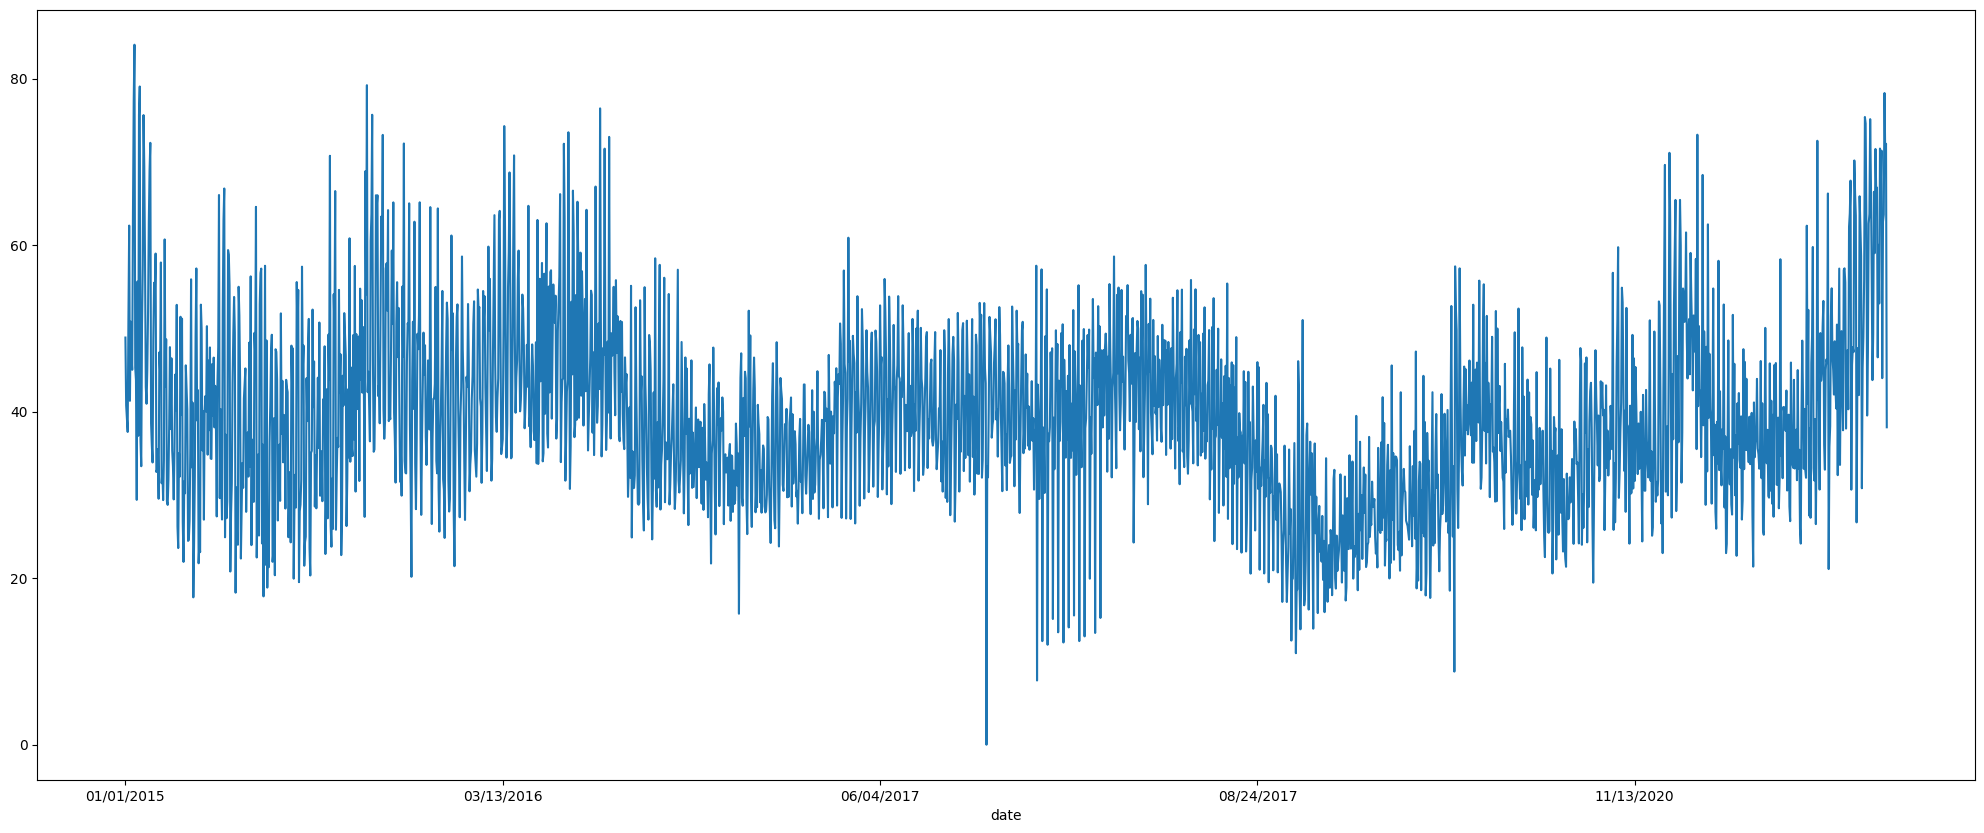

In [289]:
# Change over time
daily = (
    fin.groupby('date')['posted_wait']
      .mean()
)

daily.plot(figsize=(25,10))

<Axes: >

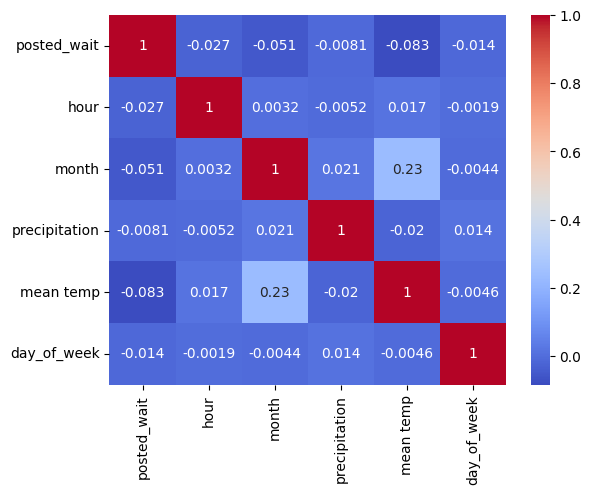

In [324]:
# Corr
col = [
    'posted_wait',
    'hour',
    'month',
    'precipitation',
    'mean temp',
    'day_of_week'

]

corr = fin[col].corr()

sns.heatmap(corr, annot=True, cmap='coolwarm')

<Axes: >

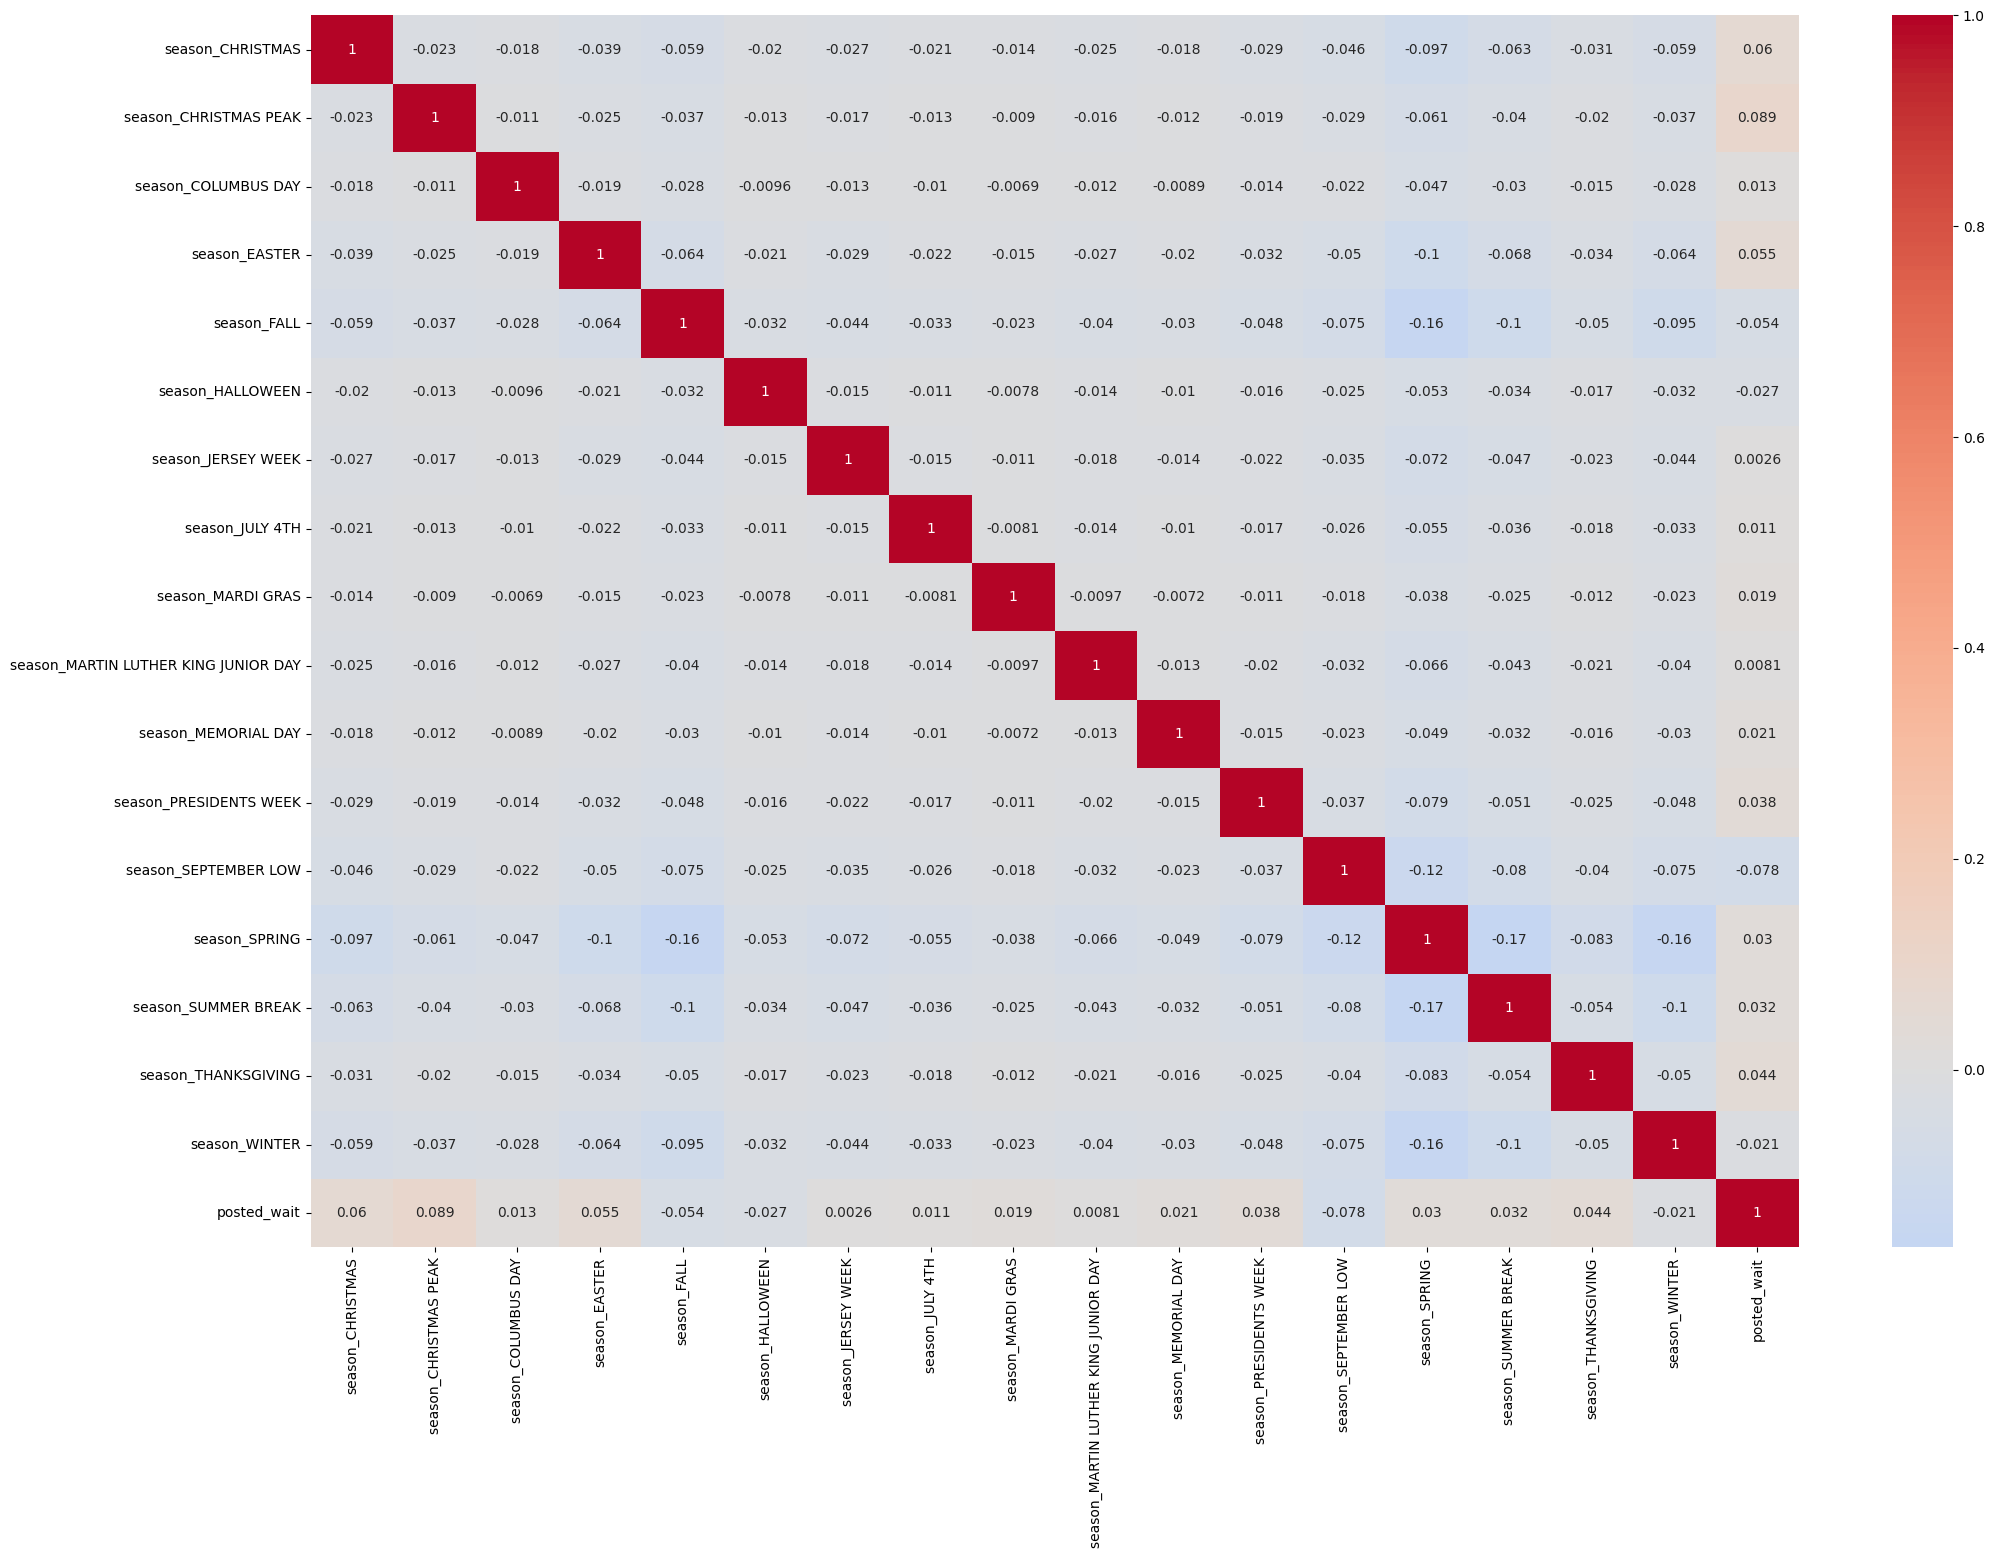

In [331]:
finseasons = fin[['season', 'posted_wait']]

seasondummies = pd.get_dummies(finseasons['season'], prefix='season')
corrdf = pd.concat([seasondummies, finseasons['posted_wait']], axis=1)
corr = corrdf.corr()

plt.figure(figsize=(24,16))
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0)

<Axes: xlabel='season', ylabel='hour'>

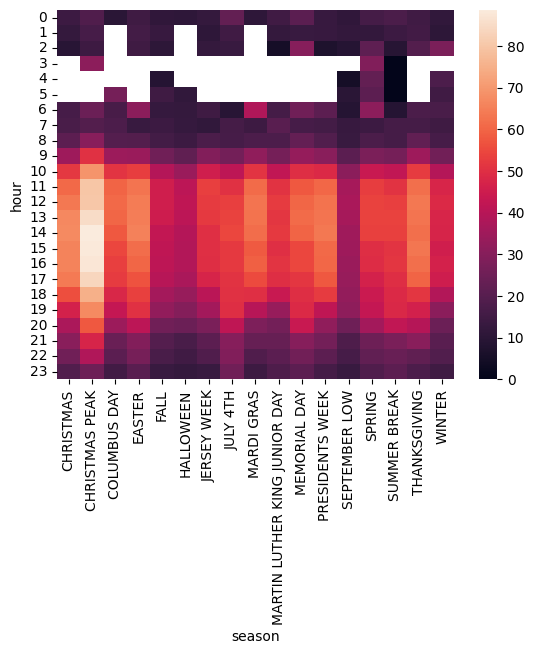

In [332]:
# Interactions
pivot = fin.pivot_table(
    values='posted_wait',
    index='hour',
    columns='season',
    aggfunc='mean'
)

sns.heatmap(pivot)

<Axes: xlabel='ride', ylabel='hour'>

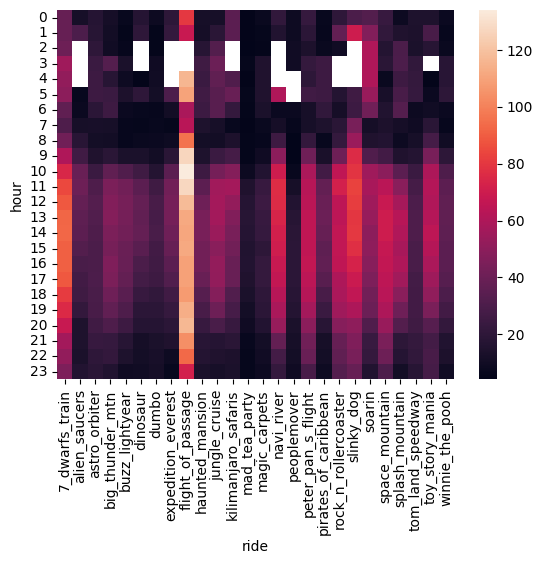

In [333]:
pivot = fin.pivot_table(
    values='posted_wait',
    index='hour',
    columns='ride',
    aggfunc='mean'
)

sns.heatmap(pivot)

Feature Engineering

In [342]:
split_index = int(len(fin) * 0.8)

train = fin.iloc[:split_index]
test = fin.iloc[split_index:]

In [ ]:
def create_features(df):
    df['is_weekend'] = df['day_of_week'].isin([5,6]).astype(int)
    
    df['temp_range'] = df['max temp'] - df['min temp']
    
    df['month_sin'] = np.sin(2*np.pi*df['month']/12)
    df['month_cos'] = np.cos(2*np.pi*df['month']/12)
    
    df['hour_sin'] = np.sin(2*np.pi*df['hour']/24)
    df['hour_cos'] = np.cos(2*np.pi*df['hour']/24)
    
    drop_cols = [
    'datetime',
    'date',
    'weekday_name'
]

    df = df.drop(columns=drop_cols)
    return df

In [343]:
fin['is_weekend'] = fin['day_of_week'].isin([5,6]).astype(int)

fin['temp_range'] = fin['max temp'] - fin['min temp']

fin['month_sin'] = np.sin(2*np.pi*fin['month']/12)
fin['month_cos'] = np.cos(2*np.pi*fin['month']/12)

fin['hour_sin'] = np.sin(2*np.pi*fin['hour']/24)
fin['hour_cos'] = np.cos(2*np.pi*fin['hour']/24)

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

model = LinearRegression()
model.fit(X_train, y_train)

preds = model.predict(X_test)

mae = mean_absolute_error(y_test, preds)
rmse = np.sqrt(mean_squared_error(y_test, preds))

print("MAE:", mae)
print("RMSE:", rmse)